### 1. Run the nanoreactor 

In [1]:
from arcskin.nanoreactor_run import SMILESPack
from arcskin.nanoreactor_run import XTBNanoReactor


In [2]:
molecules = {"NO": "[N]=O", "O2": "O=O"}


In [3]:
#sp = SMILESPack(molecules.values())
sp = SMILESPack(["[N]=O","[N]=O"])
cells, charges = sp.run_multiple(
    2, counts=[4, 4], min_dist=2.2
)  # 4 of each molecule, with a minimum distance of 2\AA
cells


[Atoms(symbols='NONONONONONONONO', pbc=False),
 Atoms(symbols='NONONONONONONONO', pbc=False)]

In [4]:
xnr = XTBNanoReactor(combination = tuple(molecules.values()), cells=cells, charges=charges, time=5)
xnr = XTBNanoReactor(combination = ("[N]=O","[N]=O"),cells=cells, charges=charges, time=5)
xnr.run(location="./example_run/")


In [5]:
xnr.trajectory_locations


['./example_run/seed_0/xtb.trj', './example_run/seed_1/xtb.trj']

### 2. Analyse the run 

In [6]:
from arcskin.nanoreactor_analysis import AnalyseNanoReactor

#anr = AnalyseNanoReactor(skip_step=20, reactants=list(molecules.values()))
anr = AnalyseNanoReactor(skip_step=20, reactants=["[N]=O","[N]=O"])

anr.read_trajectory(xnr.trajectory_locations, format="xyz")
anr.analyse_trajectories()


Warp 1.18.0 initialized:
   CUDA not enabled in this build
   Devices:
     "cpu"      : "arm"
   Kernel cache:
     /Users/badw/Library/Caches/warp/1.18.0
calculating with default calculator: aimnet


100%|██████████| 50/50 [01:35<00:00,  1.92s/it]


In [7]:
import pandas as pd

df = pd.DataFrame(anr.unique_smiles_counter).sum(axis=1).sort_values(ascending=False)
df

N#N             48.0
[N][N][O]       34.0
[O]N=O          30.0
[O][N][N][O]    25.0
O=O             19.0
[N]N(=O)=O       1.0
[O][O]           1.0
dtype: float64

In [8]:
anr.get_sensible_smiles()
possible_paths = anr.get_possible_paths_dict()
possible_paths

{0: {'reactants': ['[N]=O', '[N]=O'],
  'products': ['N#N', '[O][O]'],
  'reactants_energies': [-3535.176241480919, -3535.176241480919],
  'products_energies': [-2982.707183339265, -4091.6174217390967],
  'diff': np.float64(-3.9721221165236784)},
 1: {'reactants': ['[N]=O', '[N]=O'],
  'products': ['[N]N(=O)=O'],
  'reactants_energies': [-3535.176241480919, -3535.176241480919],
  'products_energies': [-7071.264888904947],
  'diff': np.float64(-0.9124059431087517)},
 2: {'reactants': ['[N]=O', '[N]=O'],
  'products': ['[O][N][N][O]'],
  'reactants_energies': [-3535.176241480919, -3535.176241480919],
  'products_energies': [-7073.557141686434],
  'diff': np.float64(-3.2046587245959017)}}

### 3. Calculate the Energy barriers with NEB 

In [19]:
from arcskin.make_neb_endpoints import make_endpoints

reaction_endpoints = {}
for k,v in possible_paths.items():
    try:
        reactants, products = make_endpoints(v["reactants"],v["products"],shift=3)
        reaction_endpoints[k] = {
            "reactants":reactants,
            "products":products,
            "overall":possible_paths[k]
                                 }
    except Exception:
        print(f"{k} failed")
        pass

[N]=O + [N]=O -> N#N + [O][O] | form: ['N0-N2', 'O1-O3']  break: ['N0-O1', 'N2-O3']
[N]=O + [N]=O -> [N]N(=O)=O | form: ['N0-N2', 'O1-N2']  break: ['N0-O1']
[N]=O + [N]=O -> [O][N][N][O] | form: ['N0-N2']  break: []


In [20]:
reaction_endpoints

{0: {'reactants': Atoms(symbols='NONO', pbc=False),
  'products': Atoms(symbols='NONO', pbc=False),
  'overall': {'reactants': ['[N]=O', '[N]=O'],
   'products': ['N#N', '[O][O]'],
   'reactants_energies': [-3535.176241480919, -3535.176241480919],
   'products_energies': [-2982.707183339265, -4091.6174217390967],
   'diff': np.float64(-3.9721221165236784)}},
 1: {'reactants': Atoms(symbols='NONO', pbc=False),
  'products': Atoms(symbols='NONO', pbc=False),
  'overall': {'reactants': ['[N]=O', '[N]=O'],
   'products': ['[N]N(=O)=O'],
   'reactants_energies': [-3535.176241480919, -3535.176241480919],
   'products_energies': [-7071.264888904947],
   'diff': np.float64(-0.9124059431087517)}},
 2: {'reactants': Atoms(symbols='NONO', pbc=False),
  'products': Atoms(symbols='NONO', pbc=False),
  'overall': {'reactants': ['[N]=O', '[N]=O'],
   'products': ['[O][N][N][O]'],
   'reactants_energies': [-3535.176241480919, -3535.176241480919],
   'products_energies': [-7073.557141686434],
   'diff'

In [21]:
from arcskin.run_neb import run_all

results = run_all(reaction_endpoints)

running with aimnet


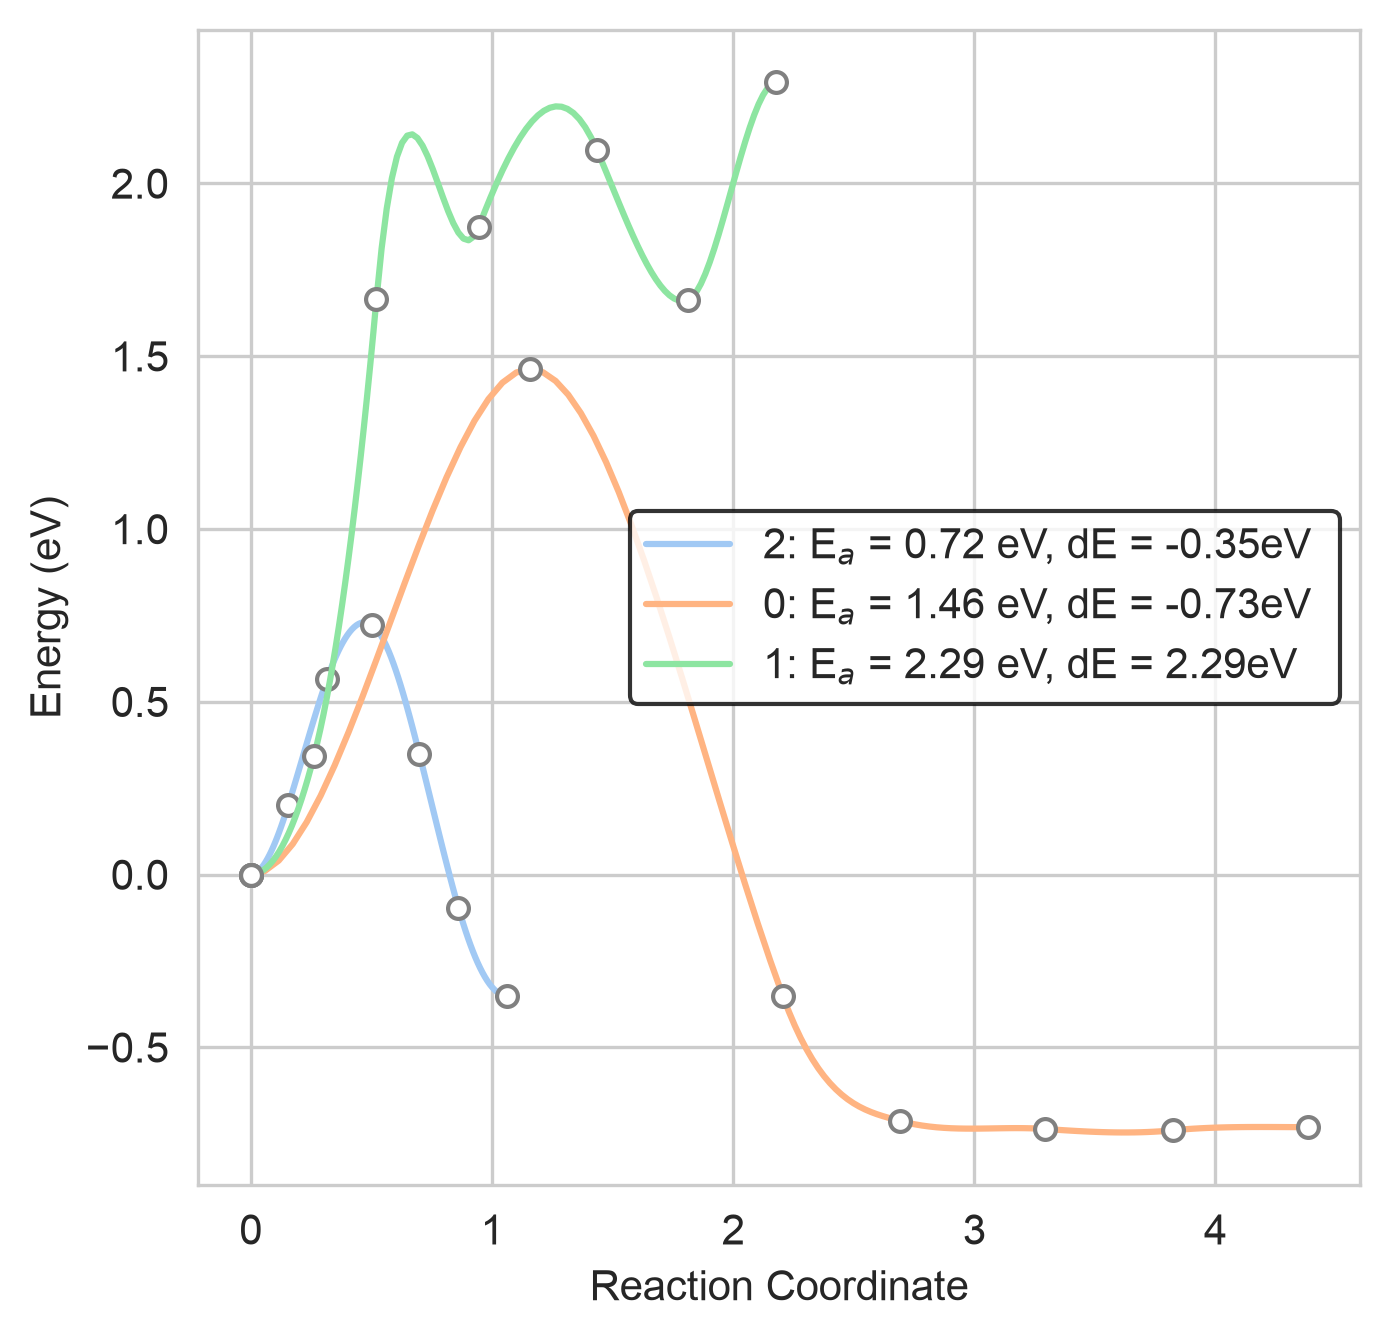

In [22]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,**kws):
    for k,v in image_dict.items():
        fit = forcecurve.fit_images(v["images"])
        Ef = fit[1].max()
        ax.plot(fit[2],fit[3],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV ')
        ax.plot(fit[0],fit[1],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(5,5),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results.T,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
    #flat_ax[i].set_title(f"expansion={nebbys[i]["expansion"]},rattle={nebbys[i]["rattle"]},nimages={nebbys[i]["nimages"]}")
ax.legend(edgecolor="black")

In [24]:
results

,Ea,dE,reactants,products,reactants_energies,products_energies,diff,images
2,0.722232,-0.350543,"[[N]=O, [N]=O]",[[O][N][N][O]],"[-3535.176241, -3535.176241]",[-7073.557142],-3.204659,"[Atoms(symbols='NONO', pbc=False, calculator=A..."
0,1.462828,-0.730992,"[[N]=O, [N]=O]","[N#N, [O][O]]","[-3535.176241, -3535.176241]","[-2982.707183, -4091.617422]",-3.972122,"[Atoms(symbols='NONO', pbc=False, calculator=A..."
1,2.292263,2.292263,"[[N]=O, [N]=O]",[[N]N(=O)=O],"[-3535.176241, -3535.176241]",[-7071.264889],-0.912406,"[Atoms(symbols='NONO', pbc=False, calculator=A..."


In [26]:
from ase.visualize import view 

view(results["images"][1],viewer="ngl")